# The Lattice Boltzmann Method (LBM)

**A mesoscopic way to simulate fluid flow — a 2D training subject**

The Lattice Boltzmann Method is an alternative to solving the Navier–Stokes equations directly.
Instead of discretising the macroscopic velocity and pressure fields, it tracks a **distribution
of particles** moving on a regular lattice, and recovers the macroscopic flow from the averages
(moments) of that distribution.

The heart of the method is a fixed **collide–stream** loop. What changes from one model to
another is the **equilibrium distribution**, which selects the equation that is solved.

This notebook presents the theory of the method and then a **subject**: a set of steps in which you
implement a 2D (D2Q9) solver and check each result against a **reference solution**. It then solves
the three 1D model equations (diffusion, advection, Burgers) on the D1Q3 lattice and cross-checks
them with the classical baselines of `fluids.ipynb`.

The code uses only `numpy` and `matplotlib`.

## Environment

```bash
pip install numpy matplotlib
```

This notebook needs only `numpy` and `matplotlib`.

## 1. Recalls on LBM

The Lattice-Boltzmann Method (LBM) solves a discretized form of the **Boltzmann equation**. In its
continuous form, using the simple Bhatnagar–Gross–Krook (BGK) approximation for the collision term:

$$\partial_t f + \boldsymbol{\xi}\cdot\nabla f = -\frac{1}{\tau}\left(f - f^{eq}\right)$$

where:

- $f(\mathbf{x},\boldsymbol{\xi},t)$ is the particle distribution function: the density of particles
  at position $\mathbf{x}$ with microscopic velocity $\boldsymbol{\xi}$ at time $t$;
- $\tau$ is the relaxation time of the BGK collision model;
- $f^{eq}$ is the Maxwell–Boltzmann equilibrium distribution, towards which $f$ relaxes.

In $D$ spatial dimensions it is defined by the local macroscopic properties:

$$f^{eq}(\mathbf{x},\boldsymbol{\xi},t) =
\frac{\rho}{(2\pi RT)^{D/2}}\exp\left(-\frac{(\boldsymbol{\xi}-\mathbf{u})^2}{2RT}\right),$$

with $R$ the specific gas constant, $T$ the temperature, $\rho$ the density and $\mathbf{u}$ the
macroscopic velocity.

## 2. The bridge from microscopic to macroscopic

The link between the microscopic world of particles (described by $f$) and the macroscopic world of
fluid dynamics is established through the **moments** of the distribution function. The physical fields
are recovered by integrating $f$ over the velocity space (in 2D, $d\boldsymbol{\xi}=d\xi_x\,d\xi_y$):

$$\rho = \int f\,d\boldsymbol{\xi}, \qquad
\rho\mathbf{u} = \int \boldsymbol{\xi}\,f\,d\boldsymbol{\xi}, \qquad
\rho E = \int \frac{|\boldsymbol{\xi}|^2}{2}\,f\,d\boldsymbol{\xi},$$

where $E$ is the total energy. By design, the equilibrium function $f^{eq}$ conserves these moments,
i.e. it satisfies the same integrals.

## 3. The core of LBM: how to properly discretise?

A Chapman–Enskog expansion shows that the Navier–Stokes equations can be derived from the Boltzmann
equation. The key idea of LBM is to solve the Boltzmann equation not on a continuous space, but on a
**discrete grid or lattice**. This discretization applies to space ($\mathbf{x}$), time ($t$), and most
importantly to the velocity space ($\boldsymbol{\xi}$). Instead of an infinite set of microscopic
velocities, we select a finite number $Q$ of discrete velocity vectors
$\{\mathbf{c}_a\}_{a=0..Q-1}$, $\mathbf{c}_a = (c_{xa}, c_{ya})$, chosen to exactly connect nodes on
the spatial grid.

We use the **D2Q9** lattice ($D=2$ dimensions, $Q=9$ velocities):

$$\mathbf{c} = \{(0,0),(\pm1,0),(0,\pm1),(\pm1,\pm1)\}, \qquad
\omega = \left(\tfrac49,\ \tfrac19,\ \tfrac19,\ \tfrac19,\ \tfrac19,\
\tfrac1{36},\ \tfrac1{36},\ \tfrac1{36},\ \tfrac1{36}\right), \qquad
c_s = \tfrac1{\sqrt3}.$$

This discretization has a profound consequence: by limiting the degrees of freedom in the velocity
space, the method can no longer conserve total energy $E$ perfectly, and the model naturally recovers
the **isothermal, weakly compressible Navier–Stokes** equations.

With this discrete set of velocities, the continuous integrals for the macroscopic moments become
simple, efficient sums over the populations $f_a$:

$$\rho = \sum_{a=0}^{Q-1} f_a, \qquad
\rho\mathbf{u} = \sum_{a=0}^{Q-1} \mathbf{c}_a\,f_a.$$

## 4. Constructing the discrete equilibrium

A naive approach would be to plug the discrete velocities into the continuous Maxwell–Boltzmann
function, but this **fails to conserve the moments** correctly. The correct approach is to design an
$f_a^{eq}$ that enforces the moment conditions **by construction**. This is exactly what a **Gauss
quadrature** does: it provides the discrete points (our lattice velocities $\mathbf{c}_a$) and the
weights ($\omega_a$) that integrate a polynomial against a Gaussian weighting function.

The trick is to expand the Maxwell–Boltzmann equilibrium as a polynomial in the macroscopic velocity
$\mathbf{u}$ (Taylor series, valid for low Mach number $\mathbf{u}\ll c_s$). The level of physics
recovered depends on the order to which we truncate the expansion.

**Order 0** in $\mathbf{u}$:
$$f_a^{eq} = \omega_a\,\rho$$

**Order 1** in $\mathbf{u}$:
$$f_a^{eq} = \omega_a\,\rho\left(1 + \frac{\mathbf{c}_a\cdot\mathbf{u}}{c_s^2}\right)$$

**Order 2** in $\mathbf{u}$:
$$f_a^{eq} = \omega_a\,\rho\left(1 + \frac{\mathbf{c}_a\cdot\mathbf{u}}{c_s^2}
+ \frac{(\mathbf{c}_a\cdot\mathbf{u})^2}{2c_s^4} - \frac{\mathbf{u}\cdot\mathbf{u}}{2c_s^2}\right)$$

Incorporating these equilibria into the BGK equation and integrating in the velocity space
demonstrates that **each order of the equilibrium leads to a distinct macroscopic equation**:

- **Order 0** → the **diffusion** equation: $\partial_t\rho = \nu\,\Delta\rho$
- **Order 1** → the **advection–diffusion** equation (with $\mathbf{u}$ constant):
  $\partial_t\rho + \mathbf{u}\cdot\nabla\rho = \nu\,\Delta\rho$
- **Order 2** → the **isothermal, weakly compressible Navier–Stokes** equations:
  $\partial_t\rho + \nabla\cdot(\rho\mathbf{u}) = 0$, and
  $\partial_t(\rho\mathbf{u}) + \nabla\cdot(\rho\mathbf{u}\mathbf{u}) + \nabla p = \mu\,\Delta\mathbf{u}$.

The diffusivity (or kinematic viscosity) is set by the relaxation time:

$$D = \nu = c_s^2\left(\tau - \tfrac12\right),$$

so we need $\tau > 1/2$ for a positive transport coefficient.

## The subject

Using the objectives above, the subject is: **build a D2Q9 LBM solver and demonstrate that the order of
the equilibrium selects the equation solved**, then improve its robustness and add boundary conditions
and body forces. Where a problem has a 1D form we solve it first on the D1Q3 lattice, then on the 2D
D2Q9 lattice, and check each result against a **reference solution**.

| Problem | Order | Equilibrium | 1D (D1Q3) | 2D (D2Q9) | Reference |
|---|---|---|---|---|---|
| Diffusion | 0 | $\omega_a\rho$ | exact heat kernel + FTCS | analytic 2D heat kernel | exact |
| Advection–diffusion | 1 | $\omega_a\rho(1+\frac{\mathbf{c}\cdot\mathbf{u}}{c_s^2})$ | exact + upwind | advected & spread Gaussian | exact |
| Burgers / Navier–Stokes | 2 | full second-order | conservative FD (shock) | Taylor–Green decay | analytic |
| Regularized collision | — | regularized | — | same physics as BGK | order-2 |
| Bonus: walls + body force | 2 + force | second-order | — | Poiseuille | analytic parabola |

The 2D nonlinear equilibrium is the multidimensional version of the $\partial_x(\tfrac12 u^2)$ flux of
the **Burgers** equation; in 1D the same machinery produces the Burgers nonlinearity (see
`fluids.ipynb`). The two solvers (D1Q3 and D2Q9) are defined in the code cells below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# D2Q9 lattice: 9 discrete velocities and their weights (isotropic up to
# 4th order), plus the opposite-direction map used for bounce-back walls.
# ----------------------------------------------------------------------
cx = np.array([0, 1, 0, -1, 0, 1, -1, -1, 1])
cy = np.array([0, 0, 1, 0, -1, 1, 1, -1, -1])
w  = np.array([4/9, 1/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/36, 1/36])
opp = np.array([0, 3, 4, 1, 2, 7, 8, 5, 6])
CS2 = 1/3          # c_s^2 for D2Q9
Q = 9

def stream(f):
    """Streaming (pull form, periodic): each population hops to the node
    reached by moving along its velocity. np.roll handles the wrap-around."""
    fs = np.empty_like(f)
    for a in range(Q):
        fs[a] = np.roll(f[a], (cx[a], cy[a]), axis=(0, 1))
    return fs

def equilibrium(rho, ux, uy, order=2):
    """Discrete equilibrium for D2Q9, truncated at the requested order in u.
    order 0 -> diffusion, order 1 -> advection-diffusion, order 2 -> NS."""
    cu = cx[:, None, None]*ux[None, :, :] + cy[:, None, None]*uy[None, :, :]
    usq = ux**2 + uy**2
    base = w[:, None, None]*rho[None, :, :]
    if order == 0:
        return base
    if order == 1:
        return base*(1 + cu/CS2)
    return base*(1 + cu/CS2 + cu**2/(2*CS2**2) - usq[None]/(2*CS2))

def macro(f):
    """Recover the macroscopic density and velocity (moments of f)."""
    rho = f.sum(axis=0)
    ux = (cx[:, None, None]*f).sum(axis=0)/rho
    uy = (cy[:, None, None]*f).sum(axis=0)/rho
    return rho, ux, uy

def transport_coeff(tau):
    """D = c_s^2 (tau - 1/2): the diffusivity (or kinematic viscosity)."""
    return CS2*(tau - 0.5)

def collide(f, feq, tau):
    """Standard BGK collision: relax each population towards equilibrium."""
    return f - (f - feq)/tau

def regularized_collide(f, feq, tau):
    """Regularized collision: project the non-equilibrium part f - feq onto
    the second-order Hermite basis, then relax the filtered part. This removes
    the non-hydrodynamic (ghost) modes that limit the robustness of BGK."""
    fneq = f - feq
    Hxx = cx**2 - CS2
    Hyy = cy**2 - CS2
    Hxy = cx*cy
    axx = (Hxx[:, None, None]*fneq).sum(axis=0)
    ayy = (Hyy[:, None, None]*fneq).sum(axis=0)
    axy = (Hxy[:, None, None]*fneq).sum(axis=0)
    fneq_reg = w[:, None, None]*(1/(2*CS2**2))*(
        Hxx[:, None, None]*axx[None, :, :]
        + 2*Hxy[:, None, None]*axy[None, :, :]
        + Hyy[:, None, None]*ayy[None, :, :])
    return feq + (1 - 1/tau)*fneq_reg

def solve(f0, tau, steps, order=2, u_advect=None, reg=False):
    """One time step is: moments -> equilibrium -> collide -> stream.
    If u_advect is given it is used as a prescribed constant advection
    velocity (advection-diffusion). If reg is True the regularized collision
    operator is used."""
    f = f0.copy()
    for _ in range(steps):
        rho, ux, uy = macro(f)
        if u_advect is not None:
            ux = np.full_like(rho, u_advect[0])
            uy = np.full_like(rho, u_advect[1])
        feq = equilibrium(rho, ux, uy, order)
        f = regularized_collide(f, feq, tau) if reg else collide(f, feq, tau)
        f = stream(f)
    return f

In [2]:
# ---- 1D D1Q3 lattice and LBM solver --------------------------------
c1 = np.array([-1, 0, 1])
w1 = np.array([1/6, 2/3, 1/6])          # distinct from the D2Q9 weights w

def stream_1d(g):
    """Streaming on D1Q3: the -1, 0, +1 populations hop left, stay, right."""
    return np.stack([np.roll(g[0], -1), g[1], np.roll(g[2], 1)])

def geq_advect(phi, u):
    """Linear equilibrium: advection-diffusion of phi at prescribed speed u."""
    return w1[:, None]*phi*(1 + 3*c1[:, None]*np.asarray(u))

def geq_burgers(u):
    """Conservation-law equilibrium with flux F(u) = u^2/2 (Burgers)."""
    return w1[:, None]*(u[None, :] + 1.5*u[None, :]**2*c1[:, None])

def run_advect(phi0, tau, u, steps):
    """Advection-diffusion: phi is transported by a prescribed velocity u."""
    g = geq_advect(phi0, u)
    for _ in range(steps):
        phi = g.sum(axis=0)
        g = stream_1d(g - (g - geq_advect(phi, u))/tau)
    return g.sum(axis=0)

def run_burgers(u0, tau, steps):
    """Burgers: the field u advects itself (conservation-law equilibrium)."""
    g = geq_burgers(u0)
    for _ in range(steps):
        u = g.sum(axis=0)
        g = stream_1d(g - (g - geq_burgers(u))/tau)
    return g.sum(axis=0)

# ---- Classical 1D baselines from fluids.ipynb (reference solutions) ----
def solve_diffusion(u0, nu, dx, dt, n_steps):
    """FTCS scheme for u_t = nu u_xx (fluids.ipynb baseline)."""
    r = nu*dt/dx**2
    u = u0.copy()
    for _ in range(n_steps):
        u[1:-1] = u[1:-1] + r*(u[2:] - 2*u[1:-1] + u[:-2])
    return u

def solve_advection(u0, c, dx, dt, n_steps):
    """Upwind scheme for u_t + c u_x = 0 (fluids.ipynb baseline)."""
    C = c*dt/dx
    u = u0.copy()
    for _ in range(n_steps):
        u[1:] = u[1:] - C*(u[1:] - u[:-1])
    return u

def burgers_inviscid(u0, dx, dt, n_steps):
    """Conservative upwind flux for inviscid Burgers (fluids.ipynb)."""
    u = u0.copy()
    for _ in range(n_steps):
        u[1:-1] = u[1:-1] - dt/dx*(0.5*u[1:-1]**2 - 0.5*u[:-2]**2)
    return u

def burgers_direct(u0, nu, dx, dt, n_steps):
    """Upwind convective flux + central diffusion for viscous Burgers."""
    u = u0.copy()
    for _ in range(n_steps):
        u[1:-1] = (u[1:-1]
                   - dt/dx*(0.5*u[1:-1]**2 - 0.5*u[:-2]**2)
                   + nu*dt/dx**2*(u[2:] - 2*u[1:-1] + u[:-2]))
    return u

def exact_diffusion_gaussian(x, t, nu, sigma):
    """Exact solution of u_t = nu u_xx from a Gaussian initial condition."""
    return sigma/np.sqrt(sigma**2 + 2*nu*t)*np.exp(-x**2/(2*(sigma**2 + 2*nu*t)))

def exact_advection(x, t, c, sigma):
    """Exact solution of u_t + c u_x = 0 from a Gaussian initial condition."""
    return np.exp(-(x - c*t)**2/(2*sigma**2))

## 1. Diffusion

$$\partial_t\varphi = D\,\partial_{xx}\varphi \quad (\text{1D}), \qquad
\partial_t\rho = \nu\,\Delta\rho \quad (\text{2D}).$$

The simplest model: the field spreads out and decays. It is recovered by the **order-0 equilibrium**
($\mathbf{u}=0$, $f_a^{eq}=\omega_a\rho$). We solve it in 1D and 2D and compare each with its
reference solution.

- **1D (D1Q3)**: a Gaussian bump vs the exact heat kernel and the **FTCS** baseline of `fluids.ipynb`.
- **2D (D2Q9)**: a Gaussian bump vs the analytic 2D heat kernel.

LBM  max error vs exact = 0.00045
FTCS max error vs exact = 0.00013


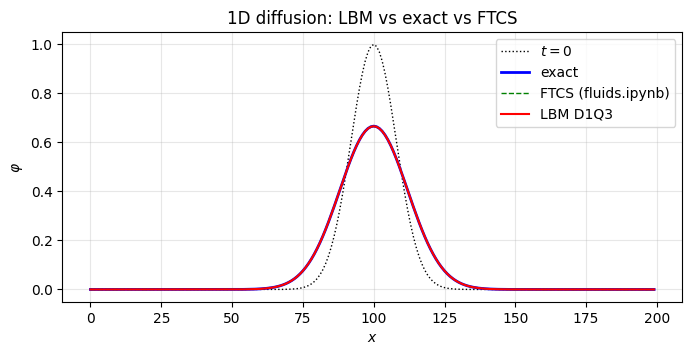

In [3]:
N = 200
x = np.arange(N)
x0 = N/2
sigma = 8.0
tau = 0.8
D = transport_coeff(tau)               # diffusion coefficient D = (tau-1/2)/3
phi0 = np.exp(-(x - x0)**2/(2*sigma**2))
t = 400

lbm = run_advect(phi0, tau, 0.0, t)                  # u = 0 -> pure diffusion
exact = exact_diffusion_gaussian(x - x0, t, D, sigma)
ftcs = solve_diffusion(phi0, D, 1.0, 1.0, t)         # classical baseline

print(f"LBM  max error vs exact = {np.max(np.abs(lbm - exact)):.5f}")
print(f"FTCS max error vs exact = {np.max(np.abs(ftcs - exact)):.5f}")

plt.figure(figsize=(8, 3.5))
plt.plot(x, phi0, 'k:', lw=1, label=r'$t=0$')
plt.plot(x, exact, 'b-', lw=2, label='exact')
plt.plot(x, ftcs, 'g--', lw=1, label='FTCS (fluids.ipynb)')
plt.plot(x, lbm, 'r-', lw=1.5, label='LBM D1Q3')
plt.legend(); plt.title('1D diffusion: LBM vs exact vs FTCS')
plt.grid(alpha=0.3); plt.xlabel('$x$'); plt.ylabel(r'$\varphi$'); plt.show()

max error vs analytic = 0.00173


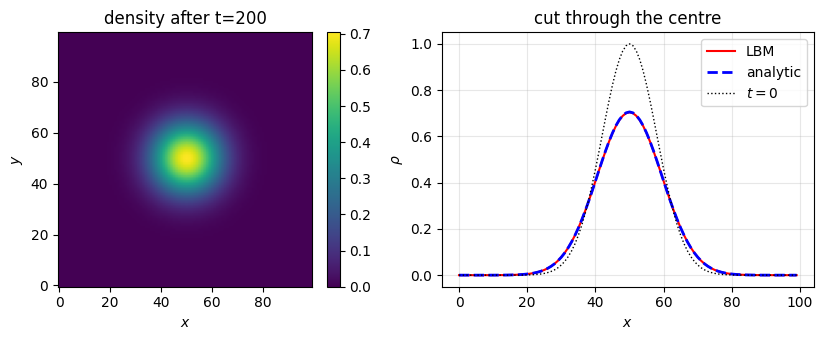

In [4]:
nx = ny = 100
x = np.arange(nx); y = np.arange(ny)
X, Y = np.meshgrid(x, y, indexing='ij')
x0 = y0 = nx/2                 # centre of the domain
sigma = 8.0                    # initial Gaussian width
tau = 0.7
nu = transport_coeff(tau)      # diffusion coefficient

rho0 = np.exp(-((X - x0)**2 + (Y - y0)**2)/(2*sigma**2))
f0 = equilibrium(rho0, np.zeros_like(rho0), np.zeros_like(rho0), order=0)

t = 200
rho = macro(solve(f0, tau, t, order=0))[0]

# reference solution: analytic 2D heat kernel
exact = (sigma**2/(sigma**2 + 2*nu*t))*np.exp(
    -((X - x0)**2 + (Y - y0)**2)/(2*(sigma**2 + 2*nu*t)))
print(f"max error vs analytic = {np.max(np.abs(rho - exact)):.5f}")

plt.figure(figsize=(9, 3.5))
plt.subplot(1, 2, 1)
plt.imshow(rho.T, origin='lower', cmap='viridis')
plt.title('density after t=200'); plt.xlabel('$x$'); plt.ylabel('$y$')
plt.colorbar(fraction=0.046, pad=0.04)
plt.subplot(1, 2, 2)
plt.plot(x, rho[:, ny//2], 'r-', lw=1.5, label='LBM')
plt.plot(x, exact[:, ny//2], 'b--', lw=2, label='analytic')
plt.plot(x, rho0[:, ny//2], 'k:', lw=1, label=r'$t=0$')
plt.legend(); plt.title('cut through the centre'); plt.grid(alpha=0.3)
plt.xlabel('$x$'); plt.ylabel(r'$\rho$')
plt.tight_layout(); plt.show()

## 2. Advection (and advection–diffusion)

$$\partial_t\varphi + u\,\partial_x\varphi = D\,\partial_{xx}\varphi \quad (\text{1D}),
\qquad \partial_t\rho + \mathbf{u}\cdot\nabla\rho = \nu\,\Delta\rho \quad (\text{2D}).$$

With a constant prescribed velocity, the **order-1 equilibrium** carries the field along while it
spreads by diffusion.

- **1D (D1Q3)**: an advected Gaussian vs the exact solution and the **upwind** baseline of
  `fluids.ipynb`.
- **2D (D2Q9)**: an advected & spread Gaussian vs the analytic solution.

peak at x=110 (expected 110.0)
LBM   max error vs exact = 0.00506
upwind max error vs exact = 0.07503


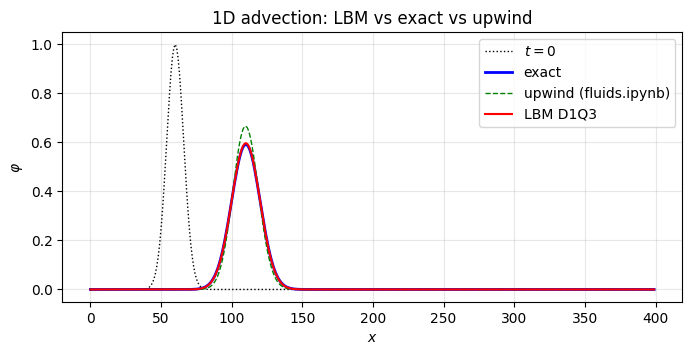

In [9]:
N = 400
x = np.arange(N)
x0 = 60.0
sigma = 6.0
tau = 0.7
D = transport_coeff(tau)
u0 = 0.1
phi0 = np.exp(-(x - x0)**2/(2*sigma**2))
t = 500

lbm = run_advect(phi0, tau, u0, t)
exact = sigma/np.sqrt(sigma**2 + 2*D*t)*np.exp(-(x - x0 - u0*t)**2/(2*(sigma**2 + 2*D*t)))
upwind = solve_advection(phi0, u0, 1.0, 1.0, t)

print(f"peak at x={x[np.argmax(lbm)]} (expected {x0 + u0*t:.1f})")
print(f"LBM   max error vs exact = {np.max(np.abs(lbm - exact)):.5f}")
print(f"upwind max error vs exact = {np.max(np.abs(upwind - exact)):.5f}")

plt.figure(figsize=(8, 3.5))
plt.plot(x, phi0, 'k:', lw=1, label=r'$t=0$')
plt.plot(x, exact, 'b-', lw=2, label='exact')
plt.plot(x, upwind, 'g--', lw=1, label='upwind (fluids.ipynb)')
plt.plot(x, lbm, 'r-', lw=1.5, label='LBM D1Q3')
plt.legend(); plt.title('1D advection: LBM vs exact vs upwind')
plt.grid(alpha=0.3); plt.xlabel('$x$'); plt.ylabel(r'$\varphi$'); plt.show()

peak at (x=42, y=36), expected (42.0, 36.0)
max error vs analytic = 0.00126


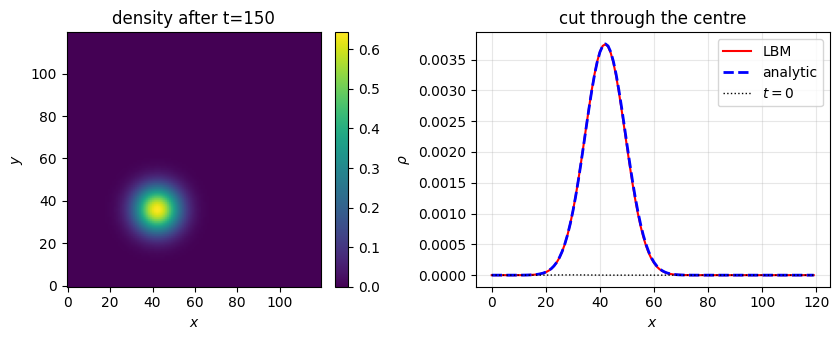

In [5]:
nx = ny = 120
x = np.arange(nx); y = np.arange(ny)
X, Y = np.meshgrid(x, y, indexing='ij')
x0 = y0 = 30.0                 # initial centre
sigma = 6.0
tau = 0.7
nu = transport_coeff(tau)
u0 = (0.08, 0.04)              # constant advection velocity

rho0 = np.exp(-((X - x0)**2 + (Y - y0)**2)/(2*sigma**2))
f0 = equilibrium(rho0, np.full_like(rho0, u0[0]), np.full_like(rho0, u0[1]), order=1)

t = 150
rho = macro(solve(f0, tau, t, order=1, u_advect=u0))[0]

# reference solution: translated and spread Gaussian
xct, yct = x0 + u0[0]*t, y0 + u0[1]*t
exact = (sigma**2/(sigma**2 + 2*nu*t))*np.exp(
    -((X - xct)**2 + (Y - yct)**2)/(2*(sigma**2 + 2*nu*t)))
print(f"peak at (x={x[np.argmax(rho[:, ny//2])]}, y={y[np.argmax(rho[nx//2, :])]}), "
      f"expected ({xct:.1f}, {yct:.1f})")
print(f"max error vs analytic = {np.max(np.abs(rho - exact)):.5f}")

plt.figure(figsize=(9, 3.5))
plt.subplot(1, 2, 1)
plt.imshow(rho.T, origin='lower', cmap='viridis')
plt.title('density after t=150'); plt.xlabel('$x$'); plt.ylabel('$y$')
plt.colorbar(fraction=0.046, pad=0.04)
plt.subplot(1, 2, 2)
plt.plot(x, rho[:, ny//2], 'r-', lw=1.5, label='LBM')
plt.plot(x, exact[:, ny//2], 'b--', lw=2, label='analytic')
plt.plot(x, rho0[:, ny//2], 'k:', lw=1, label=r'$t=0$')
plt.legend(); plt.title('cut through the centre'); plt.grid(alpha=0.3)
plt.xlabel('$x$'); plt.ylabel(r'$\rho$')
plt.tight_layout(); plt.show()

## 3. The nonlinearity: Burgers (1D) and Navier–Stokes (2D)

$$\partial_t u + u\,\partial_x u = D\,\partial_{xx}u \quad (\text{1D}), \qquad
\partial_t\mathbf{u} + (\mathbf{u}\cdot\nabla)\mathbf{u} = -\frac{1}{\rho}\nabla p
+ \nu\,\nabla^2\mathbf{u} \quad (\text{2D}).$$

The **order-2 equilibrium** introduces the quadratic convective term, the source of the nonlinearity.
In 1D this is the **Burgers** equation; in 2D it is the **Navier–Stokes** equations.

- **1D (D1Q3) Burgers**: a self-advecting pulse steepens into a **shock**, compared with the
  conservative finite-difference baseline of `fluids.ipynb`.
- **2D (D2Q9) Navier–Stokes**: the Taylor–Green vortex vs the analytic decay.

mass: LBM 30.1 -> 30.1, FD viscous 30.1, FD inviscid 30.1
steepest gradient: LBM -0.1090, FD viscous -0.0681, FD inviscid -0.1129


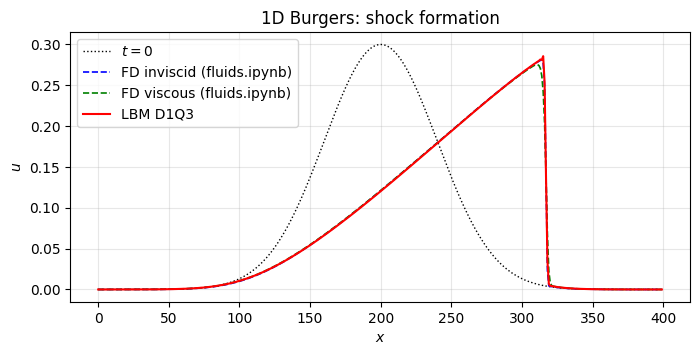

In [6]:
N = 400
x = np.arange(N)
x0 = N/2
A, sigma = 0.3, 40.0
u0 = A*np.exp(-(x - x0)**2/(2*sigma**2))
tau = 0.7
D = transport_coeff(tau)
t = 450

lbm = run_burgers(u0, tau, t)
fd_visc = burgers_direct(u0, D, 1.0, 1.0, t)        # same viscosity as the LBM
fd_inv = burgers_inviscid(u0, 1.0, 1.0, t)          # inviscid reference

print(f"mass: LBM {u0.sum():.1f} -> {lbm.sum():.1f}, "
      f"FD viscous {fd_visc.sum():.1f}, FD inviscid {fd_inv.sum():.1f}")
print(f"steepest gradient: LBM {np.gradient(lbm).min():.4f}, "
      f"FD viscous {np.gradient(fd_visc).min():.4f}, "
      f"FD inviscid {np.gradient(fd_inv).min():.4f}")

plt.figure(figsize=(8, 3.5))
plt.plot(x, u0, 'k:', lw=1, label=r'$t=0$')
plt.plot(x, fd_inv, 'b--', lw=1.2, label='FD inviscid (fluids.ipynb)')
plt.plot(x, fd_visc, 'g--', lw=1.2, label='FD viscous (fluids.ipynb)')
plt.plot(x, lbm, 'r-', lw=1.5, label='LBM D1Q3')
plt.legend(); plt.title('1D Burgers: shock formation')
plt.grid(alpha=0.3); plt.xlabel('$x$'); plt.ylabel('$u$'); plt.show()

decay factor e^(-nu k^2 t) = 0.7252
max |u| now = 0.03614  (expected 0.03626)
max velocity error vs analytic = 0.000166


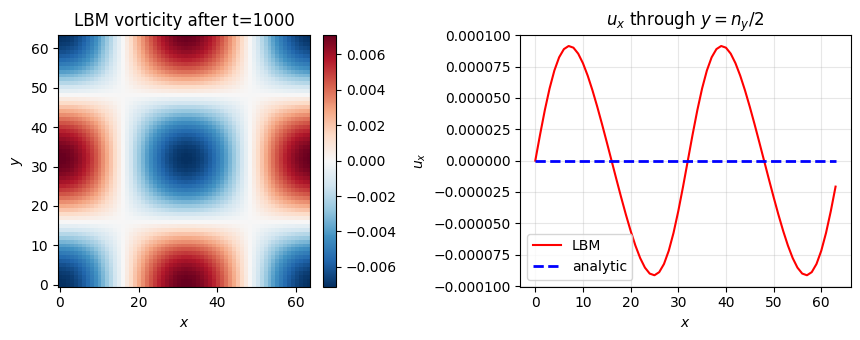

In [7]:
nx = ny = 64
x = np.arange(nx); y = np.arange(ny)
X, Y = np.meshgrid(x, y, indexing='ij')
kx = ky = 2*np.pi/nx          # one period over the domain
tau = 0.55
nu = transport_coeff(tau)
U0 = 0.05                     # low Mach number

ux0 = U0*np.cos(kx*X)*np.sin(ky*Y)
uy0 = -U0*np.sin(kx*X)*np.cos(ky*Y)
f0 = equilibrium(np.ones_like(X), ux0, uy0, order=2)

t = 1000
rho, ux, uy = macro(solve(f0, tau, t, order=2))

# reference solution: analytic Taylor-Green decay
k2 = kx**2 + ky**2
decay = np.exp(-nu*k2*t)
uxe = U0*decay*np.cos(kx*X)*np.sin(ky*Y)
uye = -U0*decay*np.sin(kx*X)*np.cos(ky*Y)
err = np.max(np.sqrt((ux - uxe)**2 + (uy - uye)**2))
print(f"decay factor e^(-nu k^2 t) = {decay:.4f}")
print(f"max |u| now = {np.max(np.sqrt(ux**2 + uy**2)):.5f}  "
      f"(expected {np.max(np.sqrt(uxe**2 + uye**2)):.5f})")
print(f"max velocity error vs analytic = {err:.6f}")

# vorticity of the reference and the LBM field
def vort(u, v):
    return np.gradient(v, axis=0) - np.gradient(u, axis=1)

plt.figure(figsize=(9, 3.5))
plt.subplot(1, 2, 1)
plt.imshow(vort(ux, uy).T, origin='lower', cmap='RdBu_r')
plt.title('LBM vorticity after t=1000'); plt.xlabel('$x$'); plt.ylabel('$y$')
plt.colorbar(fraction=0.046, pad=0.04)
plt.subplot(1, 2, 2)
plt.plot(x, ux[:, ny//2], 'r-', lw=1.5, label='LBM')
plt.plot(x, uxe[:, ny//2], 'b--', lw=2, label='analytic')
plt.legend(); plt.title(r'$u_x$ through $y=n_y/2$'); plt.grid(alpha=0.3)
plt.xlabel('$x$'); plt.ylabel(r'$u_x$')
plt.tight_layout(); plt.show()

## 4. Regularized collision operator

The BGK model relaxes $f_a$ towards $f_a^{eq}$, so we can write $f_a = f_a^{eq} + f_a^{neq}$. The
non-equilibrium part contains the viscous stress but is also polluted by non-hydrodynamic
(ghost) modes that have no meaning at the macroscopic scale. In low-viscosity (high-Reynolds) regimes
these modes can be amplified during streaming and destabilise the solver.

The regularized operator filters $f^{neq}$ before relaxing: it projects the non-equilibrium part onto
the second-order Hermite basis, $H_{xx}=c_x^2-c_s^2$, $H_{xy}=c_x c_y$, $H_{yy}=c_y^2-c_s^2$,

$$f_a^{neq,reg} = \omega_a\,\frac{1}{2c_s^4}\big(H_{xx}a_{xx}^{neq} + 2H_{xy}a_{xy}^{neq} + H_{yy}a_{yy}^{neq}\big),$$

with $a_{xx}^{neq}=\sum_a H_{xx}f_a^{neq}$, etc., then applies the collision to the filtered part.

**Reference solution**: the regularized operator must reproduce the *same* physics as BGK on a
well-resolved case. We compare both on the Taylor–Green vortex and check that they match each other and
the analytic reference.

max |f_bgk - f_reg|            = 1.062e-05
max |u_bgk - u_reg|            = 8.139e-07
L2 err vs analytic (BGK)       = 0.000166
L2 err vs analytic (regularized) = 0.000165


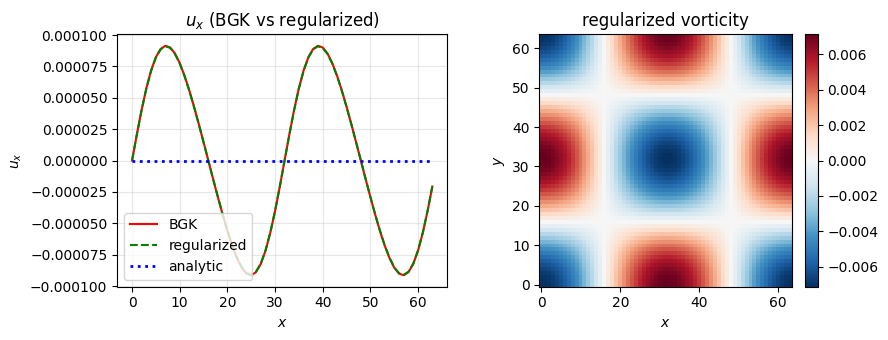

In [8]:
# Compare the standard BGK and the regularized collision operators on the
# Taylor-Green case. They should agree, and both should match the reference.
f_bgk = solve(f0, tau, t, order=2, reg=False)
f_reg = solve(f0, tau, t, order=2, reg=True)

rho_bgk, u_bgk, v_bgk = macro(f_bgk)
rho_reg, u_reg, v_reg = macro(f_reg)

print(f"max |f_bgk - f_reg|            = {np.max(np.abs(f_bgk - f_reg)):.3e}")
print(f"max |u_bgk - u_reg|            = {np.max(np.abs(u_bgk - u_reg)):.3e}")
print(f"L2 err vs analytic (BGK)       = "
      f"{np.max(np.sqrt((u_bgk-uxe)**2 + (v_bgk-uye)**2)):.6f}")
print(f"L2 err vs analytic (regularized) = "
      f"{np.max(np.sqrt((u_reg-uxe)**2 + (v_reg-uye)**2)):.6f}")

plt.figure(figsize=(9, 3.5))
plt.subplot(1, 2, 1)
plt.plot(x, u_bgk[:, ny//2], 'r-', lw=1.5, label='BGK')
plt.plot(x, u_reg[:, ny//2], 'g--', lw=1.5, label='regularized')
plt.plot(x, uxe[:, ny//2], 'b:', lw=2, label='analytic')
plt.legend(); plt.title(r'$u_x$ (BGK vs regularized)'); plt.grid(alpha=0.3)
plt.xlabel('$x$'); plt.ylabel(r'$u_x$')
plt.subplot(1, 2, 2)
plt.imshow(vort(u_reg, v_reg).T, origin='lower', cmap='RdBu_r')
plt.title('regularized vorticity'); plt.xlabel('$x$'); plt.ylabel('$y$')
plt.colorbar(fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

## 5 (bonus). Boundary conditions & body forces: Poiseuille flow

To simulate a real geometry we need walls. The **bounce-back** rule enforces the no-slip condition: a
population that streams into a wall is reflected back in the opposite direction, giving a zero average
velocity at the wall. To drive a flow we add a constant **body force** (e.g. gravity), which we inject
through an effective velocity $\mathbf{u}_{eq} = \mathbf{u} + \mathbf{F}\tau/\rho$ and a source
term in the collision.

Between two stationary walls, a constant body force produces a fully-developed **Poiseuille** profile.
**Reference solution**: with the bounce-back walls halfway between nodes, the channel of width
$H = n_y - 2$ spans $s = y - \tfrac12 \in [0, H]$ and the profile is

$$u_x(s) = \frac{a}{2\nu}\,s\,(H - s),$$

where $a$ is the acceleration (body force per unit mass) and $\nu$ the kinematic viscosity.

max |u| = 0.05401  (analytic 0.05411)
max error vs analytic = 0.000672  (relative 1.241%)


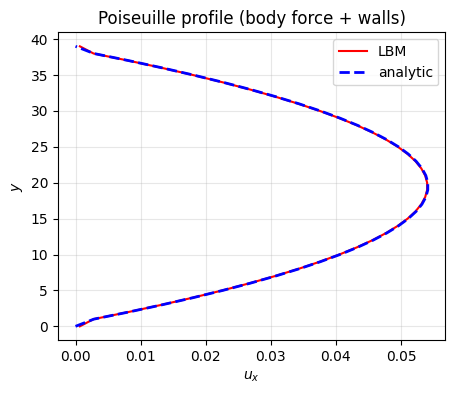

In [9]:
# Periodic streaming in x, bounce-back walls at the top and bottom (j=0, j=ny-1).
def stream_bounce_back(f):
    ny = f.shape[2]
    fs = np.empty_like(f)
    for a in range(Q):
        fs[a] = np.roll(f[a], cx[a], axis=0)          # periodic in x
    for a in range(Q):
        fs[a] = np.roll(fs[a], cy[a], axis=1)         # y streaming (periodic)
    # halfway bounce-back: populations that would come from a wall are
    # replaced by the post-collision population of the opposite direction.
    for a in range(Q):
        if cy[a] == 1:      # would stream in from the bottom wall
            fs[a, :, 1] = f[opp[a], :, 1]
        if cy[a] == -1:     # would stream in from the top wall
            fs[a, :, ny-2] = f[opp[a], :, ny-2]
    return fs

def solve_poiseuille(tau, accel, steps, nx=20, ny=40):
    rho = np.ones((nx, ny))
    ux = np.zeros_like(rho); uy = np.zeros_like(rho)
    f = equilibrium(rho, ux, uy)
    for _ in range(steps):
        rho, ux, uy = macro(f)
        Fx = rho*accel                              # body force density
        ux_eq = ux + Fx/(2*rho)                     # Guo effective velocity
        feq = equilibrium(rho, ux_eq, uy)
        cu = cx[:, None, None]*ux[None, :, :] + cy[:, None, None]*uy[None, :, :]
        cFx = cx[:, None, None]*Fx[None, :, :]
        # Guo force source term
        S = w[:, None, None]*(1 - 1/(2*tau))*(
            (cx[:, None, None] - ux[None, :, :])*Fx[None, :, :]/CS2 + cu*cFx/CS2**2)
        f = f - (f - feq)/tau + S
        f = stream_bounce_back(f)
    return macro(f)

nx, ny = 20, 40
tau = 0.6
nu = transport_coeff(tau)
accel = 1e-5
rho, ux, uy = solve_poiseuille(tau, accel, 30000, nx=nx, ny=ny)
uprof = ux.mean(axis=0)                     # average over x (fully developed)

# reference solution: walls are halfway between nodes, at j=0.5 and j=ny-1.5
y = np.arange(ny)
H = ny - 2
s = y - 0.5
u_exact = (accel/(2*nu))*np.clip(s, 0, H)*(H - np.clip(s, 0, H))
print(f"max |u| = {uprof.max():.5f}  (analytic {u_exact.max():.5f})")
print(f"max error vs analytic = {np.max(np.abs(uprof - u_exact)):.6f}  "
      f"(relative {np.max(np.abs(uprof - u_exact))/u_exact.max():.3%})")

plt.figure(figsize=(5, 4))
plt.plot(uprof, y, 'r-', lw=1.5, label='LBM')
plt.plot(u_exact, y, 'b--', lw=2, label='analytic')
plt.legend(); plt.title('Poiseuille profile (body force + walls)')
plt.xlabel(r'$u_x$'); plt.ylabel('$y$'); plt.grid(alpha=0.3); plt.show()

## References

- S. Succi, *The Lattice Boltzmann Equation for Fluid Dynamics and Beyond*, Oxford University Press, 2001.
- D. A. Wolf-Gladrow, *Lattice-Gas Cellular Automata and Lattice Boltzmann Models: An Introduction*, Springer, 2000.
- Z. Guo, C. Shu, *Lattice Boltzmann Method and Its Applications in Engineering*, World Scientific, 2013.
- J.-F. Boussuge, P. Werner, *Lattice Boltzmann Method (LBM): Training Session*, CERFACS, 2026.
- X. He, L.-S. Luo, *A priori derivation of the lattice Boltzmann equation*, Phys. Rev. E 55 (1997) R6333.